In [ ]:
from pathlib import Path

from IPython.core import display
from pipeline.extract import get_air_data, get_meteo_data

print(Path.cwd())
import sys

sys.path.insert(0, str(Path.cwd().parent))
from pipeline.transform import air_data_transform, weather_data_transform,merge_data
import matplotlib.pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
/home/alexander_user/devsrc/python/Data-engineer/khonkaen-air


In [ ]:
raw_air = get_air_data()
raw_weather = get_meteo_data()

In [ ]:
print(weather_data_transform(raw_weather).shape)
print(air_data_transform(raw_air).shape)

(168, 7)
(120, 3)


In [ ]:
print(weather_data_transform(raw_weather).head(5))
print()
print()
print(air_data_transform(raw_air).head(5))

                 time  relative_humidity_2m  temperature_2m  is_day  rain  \
0 2026-11-06 00:00:00                    88            25.3       0   0.0   
1 2026-11-06 01:00:00                    87            25.0       0   0.0   
2 2026-11-06 02:00:00                    89            24.6       0   0.0   
3 2026-11-06 03:00:00                    91            24.4       0   0.0   
4 2026-11-06 04:00:00                    92            24.3       0   0.0   

   wind_speed_10m  wind_direction_10m  
0             3.3                 264  
1             4.4                 249  
2             4.7                 230  
3             1.9                 304  
4             5.4                  21  


                 time  pm10  pm2_5
0 2026-11-06 00:00:00  13.1   13.0
1 2026-11-06 01:00:00  12.7   12.6
2 2026-11-06 02:00:00  11.9   11.8
3 2026-11-06 03:00:00  10.2   10.1
4 2026-11-06 04:00:00   8.8    8.8


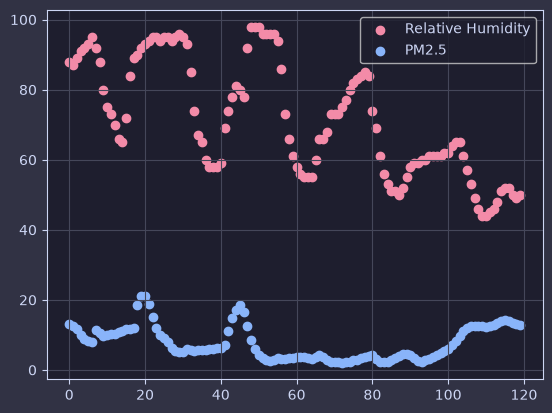

In [ ]:
weather_clean = weather_data_transform(raw_weather)
air_clean = air_data_transform(raw_air)

both = weather_clean.merge(air_clean, on="time", how="inner")
plt.scatter(both.index, both["relative_humidity_2m"], label="Relative Humidity")
plt.scatter(both.index, both["pm2_5"], label="PM2.5")
plt.legend()

In [ ]:
merged = merge_data(air_data=air_data_transform(raw_air),weather_data=weather_data_transform(raw_weather))

print(f"shape = {both.shape}")
print(f"Nah sum {both.isnull().sum()}")
print(f"shape(merge-func) = {merged.shape}")
print(f"Nuh sum (merge-func) = {merged.isnull().sum()}")

NameError: name 'merge_data' is not defined